# Regression

In [76]:
import pandas as pd 
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn import datasets
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier
import matplotlib.pyplot as plt 
from sklearn.feature_selection import SelectFromModel

## Linear Regression

### Fitting a Line

In [ ]:
# You want to train a model that represents a linear relationship between the feature and target vector
# Solution -> use Linear Regression

X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

df.head()

,cols_1,cols_2,cols_3,target
0,-1.614750,0.096755,-0.406110,-97.554448
1,0.342983,0.140556,1.126458,98.773139
2,-1.740978,0.495348,1.122390,50.054881
3,2.644343,-0.105948,-0.465310,55.815250
4,2.060827,-1.611717,-1.381549,-149.623881


In [7]:
features = df.iloc[:, :3]
target = df['target']


reg = LinearRegression()
model = reg.fit(features, target)


In [8]:
model.intercept_

-0.02980004450110324

In [9]:
model.coef_

array([43.37700426, 88.21163148, 83.20808539])

In [10]:
model.predict(features)[0]

-95.32956775600307

In [11]:
target[0]

-97.55444784185528

In [12]:
print(model.predict(features)[0] - target[0])

2.224880085852206


### Handling Interactive Effects

In [13]:
X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

df.head()

,cols_1,cols_2,cols_3,target
0,-1.614750,0.096755,-0.406110,-97.554448
1,0.342983,0.140556,1.126458,98.773139
2,-1.740978,0.495348,1.122390,50.054881
3,2.644343,-0.105948,-0.465310,55.815250
4,2.060827,-1.611717,-1.381549,-149.623881


In [15]:
features = df.iloc[:, :3]
target = df['target']

interaction = PolynomialFeatures(
    degree=3,
    include_bias=False,
    interaction_only=True
)

features_interaction = interaction.fit_transform(features)
reg = LinearRegression()
modle = reg.fit(features_interaction, target)

In [32]:
np.array(features.loc[0])

array([-1.61474986,  0.09675492, -0.40611036])

In [35]:
# To create an interaction term, we simply multiply those two values 
interaction_term = np.multiply(np.array(features.loc[0][0]), np.array(features.loc[0][1]), np.array(features.loc[0][2]))
interaction_term

/var/folders/sd/7_dvq1bs4x12529lgl1190_w0000gn/T/ipykernel_44992/3782031777.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  interaction_term = np.multiply(np.array(features.loc[0][0]), np.array(features.loc[0][1]), np.array(features.loc[0][2]))


array(-0.15623499)

In [ ]:
features_interaction[0]

array([-1.61474986,  0.09675492, -0.40611036, -0.15623499,  0.65576664,
       -0.03929317,  0.06344865])

### Fitting a Nonlinear Relationship

In [37]:
# You want to model a nonlinear relationship 
# -> Create a Polynomial Regression by including polynomial polynomial features in a linear regression model 

X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

features = df.iloc[:, :3]
target = df['target']

polynomial = PolynomialFeatures(degree=3, include_bias=False)
features_polynomial = polynomial.fit_transform(features)

reg = LinearRegression()
model = reg.fit(features_polynomial, target)

In [ ]:
np.array(features.loc[0])

array([-1.61474986,  0.09675492, -0.40611036])

In [45]:
multiply = [i for i in np.array(features.loc[0] ** 3)]
multiply

[-4.210326431854961, 0.0009057725469579466, -0.06697800326589634]

In [44]:
features_polynomial[0]

array([-1.61474986e+00,  9.67549184e-02, -4.06110357e-01,  2.60741712e+00,
       -1.56234991e-01,  6.55766643e-01,  9.36151424e-03, -3.92931745e-02,
        1.64925622e-01, -4.21032643e+00,  2.52280431e-01, -1.05889910e+00,
       -1.51165038e-02,  6.34486481e-02, -2.66313626e-01,  9.05772547e-04,
       -3.80180789e-03,  1.59573651e-02, -6.69780033e-02])

### Reducing Variance with Regularization

In [47]:
# You want to reduce the variance of your linear regression model 
# -> Use a learning algorithm that includes a shrinkage penalty (also called regularization) like ridge and lasso regression

X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

features = df.iloc[:, :3]
target = df['target']

scaler = StandardScaler()

features_standardized = scaler.fit_transform(features)

regression = Ridge(alpha=0.5)

model = regression.fit(features_standardized, target)

In [50]:
regr_cv = RidgeCV(alphas=[0.1, 1.0, 10.0])
model_cv = regr_cv.fit(features_standardized, target)
model_cv.coef_

array([43.06778031, 88.14863933, 83.51712381])

In [51]:
model_cv.alpha_

0.1

### Reducing Features with Lasso Regression

In [53]:
# You want to simplify your linear regression model by reducing the number of features 
# -> Use a lasso regression 

X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

features = df.iloc[:, :3]
target = df['target']

scaler = StandardScaler()
features_standardized = scaler.fit_transform(features)

regression = Lasso(alpha=0.5)
model = regression.fit(features_standardized, target)

In [54]:
model.coef_

array([42.55979768, 87.64581828, 83.00378909])

## Tree and Forest

### Training a Decision Tree Classifier

In [57]:
### You need to train a classifier using a decision tree 
# -> Use DecisionTreeClassifier 

iris = datasets.load_iris()
features = iris.data 
target = iris.target 

decision_tree = DecisionTreeClassifier(random_state=42)
model = decision_tree.fit(features, target)

In [58]:
# Make new observation 
observation = [[5, 4, 3, 2]]

# Predict observation's class 
model.predict(observation)

array([1])

In [59]:
# We can also see the predicted class probabilities of the observation 
model.predict_proba(observation)

array([[0., 1., 0.]])

### Training a Decision Tree Regressor 


In [61]:
X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

features = df.iloc[:, :3]
target = df['target']

decision_tree = DecisionTreeRegressor(random_state=0)
model = decision_tree.fit(features, target)


In [63]:
# Make new observation 
observation = [[0.02, 16, 25]]
model.predict(observation)

/usr/local/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


array([385.86733107])

### Training a Random Forest Classifier

In [65]:
iris = datasets.load_iris()
features = iris.data 
target = iris.target 

random_forest = RandomForestClassifier(random_state=42, n_jobs=-1)
model = random_forest.fit(features, target)

# Make new observation 
observation = [[5, 4, 3, 2]]

# Predict observation class 
model.predict(observation)

array([1])

### Training a Random Forest Regressor

In [67]:
X, y = make_regression(
    n_samples=10000,
    n_features=3,
    noise=10,
    random_state=42
)

df = pd.DataFrame(X, columns=['cols_1', 'cols_2', 'cols_3'])
df['target'] = y 

features = df.iloc[:, :3]
target = df['target']

random_forest = RandomForestRegressor(random_state=42, n_jobs=-1)

model = random_forest.fit(features, target)

### Identifying Important Features in Random Forest

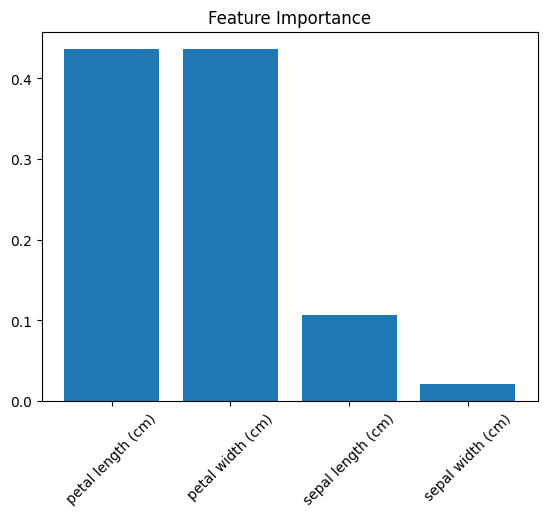

In [71]:
### You need to know which features are most important in a random forest model 
# -> Calculate and visualize the importance of each feature 

# Load data
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Train model
model = RandomForestClassifier(random_state=42, n_jobs=-1)
model.fit(X, y)

# Ambil feature importance
importances = model.feature_importances_

# Sorting
indices = np.argsort(importances)[::-1]
names = [iris.feature_names[i] for i in indices]

# Plot
plt.figure()
plt.title('Feature Importance')
plt.bar(range(X.shape[1]), importances[indices])
plt.xticks(range(X.shape[1]), names, rotation=45)
plt.show()

### Selecting Important Features in Random Forest

In [73]:
### You need to conduct feature selection on a random forest 
# -> Identify the importances features and retrain the model using only the most important features 

iris = datasets.load_iris()
features = iris.data 
target = iris.target 

random_forest = RandomForestClassifier(random_state=42, n_jobs=-1)

# Create object that selects features with importance greater that or equal to a threshold 
selector = SelectFromModel(random_forest, threshold=0.3)

features_important = selector.fit_transform(features, target)

model = random_forest.fit(features_important, target)

### Handling Imbalanced Classes 

In [74]:
# Load data
iris = datasets.load_iris()
features = iris.data
target = iris.target

# Make class highly imbalanced by removing first 40 observations
features = features[40:,:]
target = target[40:]
    
# Create target vector indicating if class 0, otherwise 1
target = np.where((target == 0), 0, 1)
    
# Create random forest classifier object
randomforest = RandomForestClassifier(
        random_state=0, n_jobs=-1, class_weight="balanced")

# Train model
model = randomforest.fit(features, target)

### Controlling Tree Size

In [75]:
### You want to manually determine the structure and size of a decision tree 
# -> Use the tree structure parameters in scikit-learn tree-based learning algorithm

# Load data
iris = datasets.load_iris()
features = iris.data
target = iris.target

# Create decision tree classifier object
decisiontree = DecisionTreeClassifier(random_state=0,
                                        max_depth=None,
                                        min_samples_split=2,
                                        min_samples_leaf=1,
                                        min_weight_fraction_leaf=0,
                                        max_leaf_nodes=None,
                                        min_impurity_decrease=0)
# Train model
model = decisiontree.fit(features, target)

### Improving Performance Through Boosting 

In [77]:
### You need a model with better performance than decision trees or random forest 
# -> Train a boosted model using AdaBoostClassifier or AdaBoosttRegressor

# Load data
iris = datasets.load_iris()
features = iris.data
target = iris.target

# Create adaboost tree classifier object
adaboost = AdaBoostClassifier(random_state=0) 

# Train model
model = adaboost.fit(features, target)

### Evaluating Random Forest with Out-of-Bag Errors 

In [78]:
### You need to evaluate a random forest model without using cross-validation 
# -> calculate the models out-of-bag score 

# Load data
iris = datasets.load_iris()
features = iris.data
target = iris.target

# Create random tree classifier object
randomforest = RandomForestClassifier(
        random_state=0, n_estimators=1000, oob_score=True, n_jobs=-1)

# Train model
model = randomforest.fit(features, target) 

# View out-of-bag-error
randomforest.oob_score_

0.9533333333333334